In [1]:
# ============================================================
# CELL 0: MOUNT GOOGLE DRIVE
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ============================================================
# CELL 1: INSTALL DEPENDENCIES
# ============================================================
!pip install torch torchvision scikit-learn -q

In [3]:
# ============================================================
# CELL 2: IMPORTS
# ============================================================
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import os
import warnings
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

In [ ]:
# ============================================================
# CELL 3: TRAINING HYPERPARAMETERS USED
# ------------------------------------------------------------
# NOTE: these are the values used in THIS run, not all of them
# are the argparse defaults in the original cgcnn/main.py.
# Original repo defaults for reference: epochs=30, batch_size=256.
# We deliberately used epochs=100 and batch_size=64 below; state
# this explicitly in the paper so results aren't misread as an
# unmodified run of the original defaults.
# ============================================================

EPOCHS        = 100
BATCH_SIZE    = 64
TRAIN_RATIO   = None
VAL_RATIO     = 0.1
TEST_RATIO    = 0.1
LR            = 0.01
LR_MILESTONES = [100]
LR_GAMMA      = 0.1
WEIGHT_DECAY  = 0
MOMENTUM      = 0.9
PRINT_FREQ    = 10

effective_train = round(1.0 - VAL_RATIO - TEST_RATIO, 2)

print("=" * 50)
print("  CGCNN TRAINING HYPERPARAMETERS (this run)")
print("=" * 50)
print(f"  Epochs             : {EPOCHS}   (original repo default: 30)")
print(f"  Batch size         : {BATCH_SIZE}   (original repo default: 256)")
print(f"  Train / Val / Test : {effective_train} / {VAL_RATIO} / {TEST_RATIO}")
print(f"  Train ratio        : None (remainder after val+test)")
print(f"  Learning rate      : {LR}")
print(f"  LR milestones      : {LR_MILESTONES}")
print(f"  LR gamma           : {LR_GAMMA}")
print(f"  Weight decay       : {WEIGHT_DECAY}")
print(f"  Momentum           : {MOMENTUM}")
print("=" * 50)


In [5]:
# ============================================================
# CELL 4: CUSTOM DATASET — loads targets upfront
# ============================================================
class CrystalGraphDataset(Dataset):
    def __init__(self, pkl_path):
        import pickle
        print("Loading graphs from pkl...")
        with open(pkl_path, "rb") as f:
            self.graphs = pickle.load(f)
        self.targets = [float(g["target"].item()) for g in self.graphs]
        print(f"✓ Loaded {len(self.graphs)} graphs from {pkl_path}")

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, idx):
        data    = self.graphs[idx]
        atom_fea    = data["atom_fea"].float()
        nbr_fea     = data["nbr_fea"].float()
        nbr_fea_idx = data["nbr_fea_idx"].long()
        target      = torch.tensor([float(data["target"].item())]).float()
        cif_id      = data["id"]

        return (atom_fea, nbr_fea, nbr_fea_idx), target, cif_id

In [6]:
# ============================================================
# CELL 5: COLLATE FUNCTION
# ============================================================
def collate_graphs(batch):
    """
    Collates variable-size crystal graphs into batched tensors.
    Mirrors CGCNN's original collate_pool logic.
    """
    batch_atom_fea    = []
    batch_nbr_fea     = []
    batch_nbr_fea_idx = []
    batch_target      = []
    batch_ids         = []
    crystal_atom_idx  = []

    base_idx = 0
    for (atom_fea, nbr_fea, nbr_fea_idx), target, cif_id in batch:
        n_i = atom_fea.shape[0]

        batch_atom_fea.append(atom_fea)
        batch_nbr_fea.append(nbr_fea)
        batch_nbr_fea_idx.append(nbr_fea_idx + base_idx)
        batch_target.append(target)
        batch_ids.append(cif_id)
        crystal_atom_idx.append(
            torch.arange(base_idx, base_idx + n_i, dtype=torch.long)
        )
        base_idx += n_i

    return (
        torch.cat(batch_atom_fea,    dim=0),
        torch.cat(batch_nbr_fea,     dim=0),
        torch.cat(batch_nbr_fea_idx, dim=0),
        crystal_atom_idx
    ), torch.cat(batch_target, dim=0), batch_ids

In [7]:
# ============================================================
# CELL 6: LOAD DATASET AND SPLIT
# ============================================================
# ── set BOTH fields together whenever you swap datasets ───────────────
PKL_PATH     = "/content/drive/MyDrive/cgcnn_graphs_heusler.pkl"
DATASET_NAME = "heusler"       # must match: "heusler" | "pyrochlore" | "skutterudite"
# ─────────────────────────────────────────────────────────────────────

dataset = CrystalGraphDataset(PKL_PATH)

total   = len(dataset)
n_val   = int(total * VAL_RATIO)
n_test  = int(total * TEST_RATIO)
n_train = total - n_val - n_test

train_set, val_set, test_set = random_split(
    dataset, [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_graphs, num_workers=1)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=collate_graphs, num_workers=1)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=collate_graphs, num_workers=1)

print(f"Dataset      : {DATASET_NAME}")
print(f"Train: {n_train} | Val: {n_val} | Test: {n_test}")
print(f"Effective split: {n_train/total:.2f} / {n_val/total:.2f} / {n_test/total:.2f}")
print("⚠  Remember to re-run Cell 8 (Normalizer) after changing DATASET_NAME.")

Loading graphs from pkl...
✓ Loaded 8129 graphs from /content/drive/MyDrive/cgcnn_graphs.pkl
Train: 6505 | Val: 812 | Test: 812
Effective split: 0.80 / 0.10 / 0.10


In [8]:
# ============================================================
# CELL 7: CLONE CGCNN FOR MODEL ARCHITECTURE ONLY
# ============================================================
!git clone https://github.com/txie-93/cgcnn.git
import sys
sys.path.insert(0, "/content/cgcnn")
from cgcnn.model import CrystalGraphConvNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = CrystalGraphConvNet(
    orig_atom_fea_len = 92,
    nbr_fea_len       = 41,
    atom_fea_len      = 64,
    n_conv            = 3,
    h_fea_len         = 128,
    n_h               = 1,
    classification    = False
).to(device)

print("✓ Model built with random weights")
print(f"  Parameters: {sum(p.numel() for p in model.parameters()):,}")

Cloning into 'cgcnn'...
remote: Enumerating objects: 127, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 127 (delta 38), reused 36 (delta 36), pack-reused 77 (from 1)
Receiving objects: 100% (127/127), 7.22 MiB | 16.29 MiB/s, done.
Resolving deltas: 100% (61/61), done.
Device: cuda
✓ Model built with random weights
  Parameters: 80,833


In [9]:
# ============================================================
# CELL 8: NORMALIZER
# ============================================================
class Normalizer(object):
    def __init__(self, tensor, domain_name="unknown"):
        self.mean        = torch.mean(tensor)
        self.std         = torch.std(tensor)
        self.domain_name = domain_name          # ← tracks which dataset owns this normalizer

    def norm(self, tensor):
        return (tensor - self.mean) / self.std

    def denorm(self, normed_tensor):
        return normed_tensor * self.std + self.mean

    def save(self, path):
        """Persist normalizer alongside the model checkpoint."""
        torch.save({"mean": self.mean, "std": self.std,
                    "domain": self.domain_name}, path)
        print(f"✓ Normalizer saved → {path}  (domain: {self.domain_name})")

    @classmethod
    def load(cls, path):
        """Re-load a saved normalizer; always verify domain matches the model."""
        d   = torch.load(path)
        obj = cls.__new__(cls)
        obj.mean        = d["mean"]
        obj.std         = d["std"]
        obj.domain_name = d["domain"]
        print(f"✓ Normalizer loaded ← {path}  (domain: {obj.domain_name})")
        return obj

# ── fit on training-split targets of the CURRENT dataset ──────────────
DATASET_NAME  = "heusler"       # ← change to "pyrochlore" / "skutterudite" / etc.
                                  #   every time you change PKL_PATH in Cell 6

train_targets = torch.tensor(
    [dataset.targets[i] for i in train_set.indices]
)

normalizer = Normalizer(train_targets, domain_name=DATASET_NAME)
print(f"✓ Normalizer [{DATASET_NAME}] — mean: {normalizer.mean:.4f}, "
      f"std: {normalizer.std:.4f}")

✓ Normalizer — mean: 0.1860, std: 1.2594


In [ ]:
# ============================================================
# CELL 9: TRAINING LOOP
# ------------------------------------------------------------
# FIX: the original run trained for a fixed number of epochs and
# then evaluated the TEST set with whatever weights happened to be
# in `model` after the last epoch. The original cgcnn/main.py does
# NOT do this — it tracks the best validation MAE across epochs,
# checkpoints that best model, reloads it, and only then evaluates
# on the test set ("Evaluate Model on Test Set" in main.py using
# model_best.pth.tar). Reporting last-epoch numbers instead of
# best-validated numbers can understate or overstate performance
# depending on whether the model over/under-fit near the end of
# training, and it is inconsistent with how the MEGNet comparison
# was run (best-val checkpoint selection). This cell now tracks and
# keeps the best-validation-MAE state_dict in memory (`best_state`),
# matching the original CGCNN behavior.
# ============================================================
import copy

criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=LR,
                      momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=LR_MILESTONES, gamma=LR_GAMMA
)

history = {"train_loss": [], "train_mae": [], "val_loss": [], "val_mae": []}

def run_epoch(loader, training=True, norm=None):   # ← norm is now explicit
    """
    norm : Normalizer instance — must belong to the same domain the model
           was trained on.  Passing None raises immediately so the mismatch
           is caught at the call site, not buried in a bad metric.
    """
    if norm is None:
        raise ValueError(
            "run_epoch requires an explicit Normalizer. "
            "Pass the normalizer that matches the model's training domain."
        )

    model.train() if training else model.eval()
    total_loss, total_mae, n = 0.0, 0.0, 0

    for (atom_fea, nbr_fea, nbr_fea_idx, crystal_atom_idx), target, _ in loader:
        atom_fea         = atom_fea.to(device)
        nbr_fea          = nbr_fea.to(device)
        nbr_fea_idx      = nbr_fea_idx.to(device)
        crystal_atom_idx = [x.to(device) for x in crystal_atom_idx]
        target_norm      = norm.norm(target).to(device)          # ← uses passed normalizer

        if training:
            optimizer.zero_grad()
            output = model(atom_fea, nbr_fea, nbr_fea_idx, crystal_atom_idx)
            loss   = criterion(output.squeeze(), target_norm.squeeze())
            loss.backward()
            optimizer.step()
        else:
            with torch.no_grad():
                output = model(atom_fea, nbr_fea, nbr_fea_idx, crystal_atom_idx)
                loss   = criterion(output.squeeze(), target_norm.squeeze())

        pred_denorm = norm.denorm(output.squeeze().detach().cpu())   # ← uses passed normalizer
        mae  = torch.mean(torch.abs(pred_denorm - target.squeeze())).item()
        bs   = target.size(0)
        total_loss += loss.item() * bs
        total_mae  += mae * bs
        n          += bs

    return total_loss / n, total_mae / n


# ── track the best-validation-MAE checkpoint, like original main.py ───
best_val_mae = float("inf")
best_state   = None
best_epoch   = -1

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_mae = run_epoch(train_loader, training=True,  norm=normalizer)
    vl_loss, vl_mae = run_epoch(val_loader,   training=False, norm=normalizer)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["train_mae"].append(tr_mae)
    history["val_loss"].append(vl_loss)
    history["val_mae"].append(vl_mae)

    if vl_mae < best_val_mae:
        best_val_mae = vl_mae
        best_epoch   = epoch
        best_state   = copy.deepcopy(model.state_dict())

    print(f"{epoch:>6} | {tr_loss:>10.4f} {tr_mae:>10.4f} | {vl_loss:>10.4f} {vl_mae:>10.4f}"
          f"{'  <- best val' if epoch == best_epoch else ''}")

print(f"\n✓ Training complete — best val MAE {best_val_mae:.4f} at epoch {best_epoch}")

# Load the best-validation checkpoint back into `model` before any
# downstream test evaluation or saving — this is the model that gets
# reported and shipped, not whatever the last epoch left behind.
model.load_state_dict(best_state)
model.eval()
print("✓ Loaded best-validation-MAE weights into `model` for evaluation/saving")


In [ ]:
# ============================================================
# CELL 10: TEST EVALUATION
# ------------------------------------------------------------
# `model` now holds the best-validation-MAE weights (loaded at the
# end of Cell 9), so this evaluates the same checkpoint that will be
# saved and reported — not the final-epoch weights.
# ============================================================
test_loss, test_mae = run_epoch(test_loader, training=False, norm=normalizer)

model.eval()
all_preds, all_targets, all_ids = [], [], []

with torch.no_grad():
    for (atom_fea, nbr_fea, nbr_fea_idx, crystal_atom_idx), target, ids in test_loader:
        atom_fea         = atom_fea.to(device)
        nbr_fea          = nbr_fea.to(device)
        nbr_fea_idx      = nbr_fea_idx.to(device)
        crystal_atom_idx = [x.to(device) for x in crystal_atom_idx]

        output      = model(atom_fea, nbr_fea, nbr_fea_idx, crystal_atom_idx)
        pred_denorm = normalizer.denorm(output.squeeze().cpu())

        for p, t, i in zip(pred_denorm.detach().numpy().flatten(),
                           target.numpy().flatten(), ids):
            all_preds.append(float(p))
            all_targets.append(float(t))
            all_ids.append(i)

all_preds   = np.array(all_preds,   dtype=float)
all_targets = np.array(all_targets, dtype=float)
errors      = all_preds - all_targets
test_r2     = r2_score(all_targets, all_preds)

print("=" * 50)
print("  FINAL EVALUATION RESULTS (best-val-MAE checkpoint)")
print("=" * 50)
print(f"  Best val epoch : {best_epoch}")
print(f"  Train Loss : {history['train_loss'][best_epoch-1]:.4f}")
print(f"  Train MAE  : {history['train_mae'][best_epoch-1]:.4f}")
print(f"  Val   Loss : {history['val_loss'][best_epoch-1]:.4f}")
print(f"  Val   MAE  : {history['val_mae'][best_epoch-1]:.4f}")
print(f"  Test  Loss : {test_loss:.4f}")
print(f"  Test  MAE  : {test_mae:.4f}")
print(f"  Test  R²   : {test_r2:.4f}")
print("=" * 50)


In [ ]:
# ============================================================
# CELL 10b: SAVE CHECKPOINT  (run after every training session)
# ------------------------------------------------------------
# Saves best_state explicitly (best-validation-MAE weights), not
# model.state_dict() from whatever epoch training happened to stop
# at. `model` already holds best_state after Cell 9, but we save
# `best_state` directly here so this cell is correct even if cells
# are re-run out of order.
# ============================================================
CKPT_DIR = "/content/drive/MyDrive/cgcnn_checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

# Save best-validation-MAE model weights
model_path = os.path.join(CKPT_DIR, f"cgcnn_{DATASET_NAME}.pt")
torch.save(best_state, model_path)

# Save normalizer — ALWAYS alongside the model, NEVER separately
norm_path  = os.path.join(CKPT_DIR, f"normalizer_{DATASET_NAME}.pt")
normalizer.save(norm_path)

print(f"✓ Model (best val epoch {best_epoch}) saved → {model_path}")
print(f"✓ Normalizer saved → {norm_path}")
print(f"  Training domain  : {DATASET_NAME}")


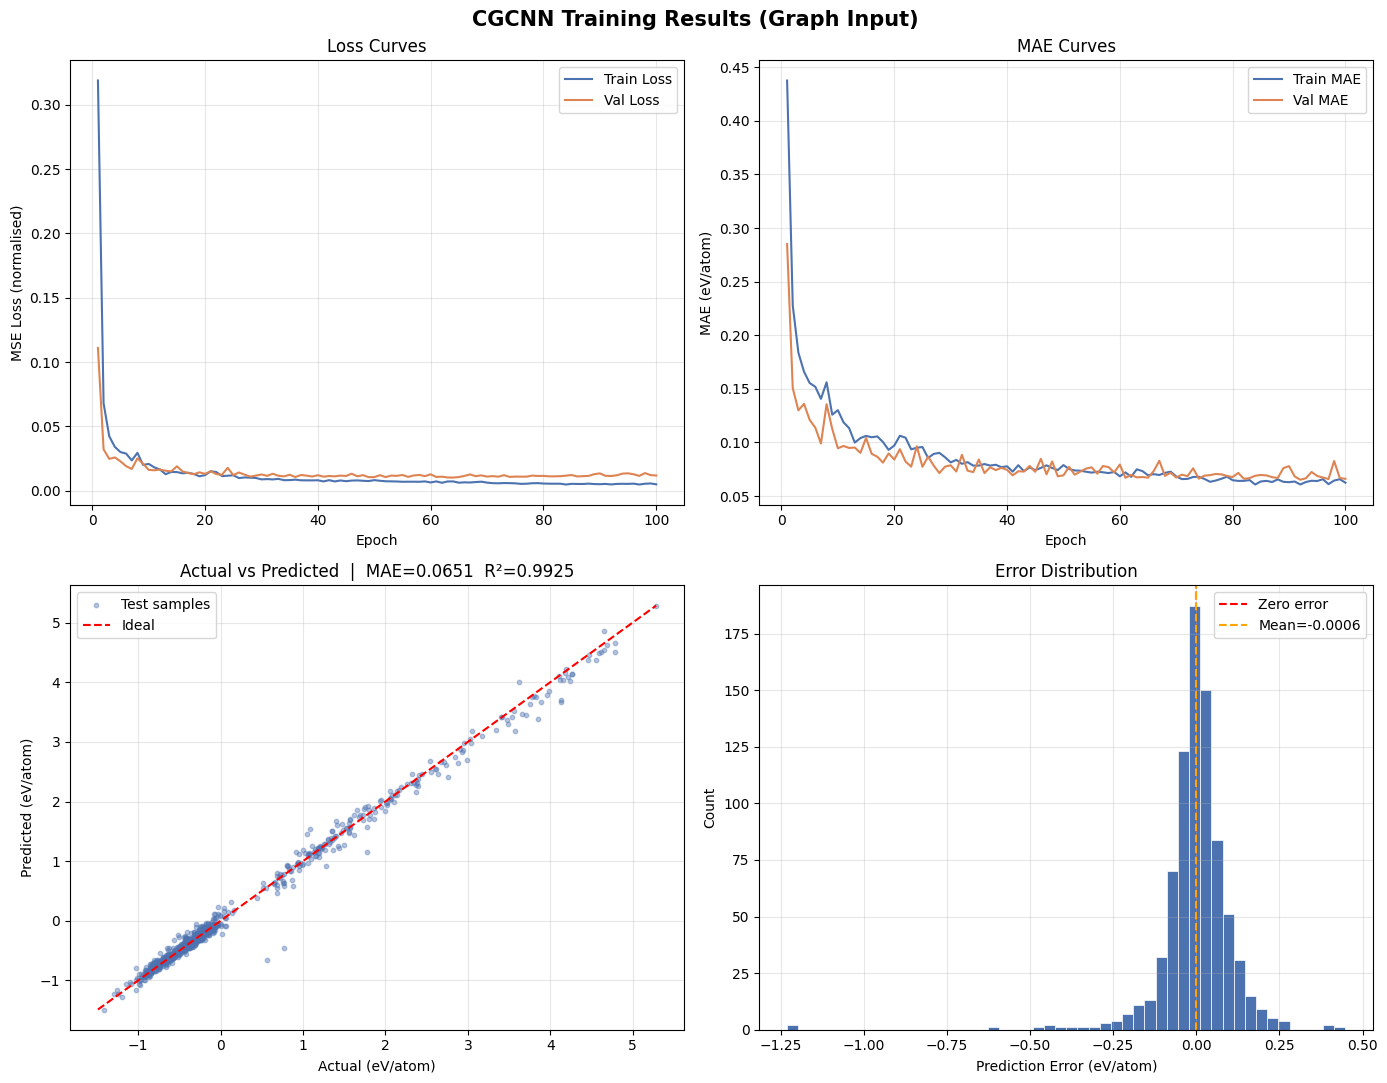

✓ Plot saved to /content/cgcnn_results_graphs.png


In [12]:
# ============================================================
# CELL 11: PLOTS
# ============================================================
epochs_x = range(1, EPOCHS + 1)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle("CGCNN Training Results (Graph Input)", fontsize=15, fontweight="bold")

# Loss curves
ax = axes[0, 0]
ax.plot(epochs_x, history["train_loss"], label="Train Loss", color="#4C72B0")
ax.plot(epochs_x, history["val_loss"],   label="Val Loss",   color="#DD8452")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE Loss (normalised)")
ax.set_title("Loss Curves"); ax.legend(); ax.grid(True, alpha=0.3)

# MAE curves
ax = axes[0, 1]
ax.plot(epochs_x, history["train_mae"], label="Train MAE", color="#4C72B0")
ax.plot(epochs_x, history["val_mae"],   label="Val MAE",   color="#DD8452")
ax.set_xlabel("Epoch"); ax.set_ylabel("MAE (eV/atom)")
ax.set_title("MAE Curves"); ax.legend(); ax.grid(True, alpha=0.3)

# Actual vs Predicted
ax = axes[1, 0]
mn = min(all_targets.min(), all_preds.min())
mx = max(all_targets.max(), all_preds.max())
ax.scatter(all_targets, all_preds, alpha=0.4, s=10, color="#4C72B0", label="Test samples")
ax.plot([mn, mx], [mn, mx], "r--", linewidth=1.5, label="Ideal")
ax.set_xlabel("Actual (eV/atom)"); ax.set_ylabel("Predicted (eV/atom)")
ax.set_title(f"Actual vs Predicted  |  MAE={test_mae:.4f}  R²={test_r2:.4f}")
ax.legend(); ax.grid(True, alpha=0.3)

# Error distribution
ax = axes[1, 1]
ax.hist(errors, bins=50, color="#4C72B0", edgecolor="white", linewidth=0.5)
ax.axvline(0,             color="red",    linestyle="--", linewidth=1.5, label="Zero error")
ax.axvline(errors.mean(), color="orange", linestyle="--", linewidth=1.5,
           label=f"Mean={errors.mean():.4f}")
ax.set_xlabel("Prediction Error (eV/atom)"); ax.set_ylabel("Count")
ax.set_title("Error Distribution"); ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/content/cgcnn_results_graphs.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Plot saved to /content/cgcnn_results_graphs.png")

In [13]:
# ============================================================
# CHECK DEPENDENCY VERSIONS
# ============================================================
import torch
import torchvision
import sklearn
import numpy as np
import matplotlib
import pickle
import sys

print("=" * 50)
print("  DEPENDENCY VERSIONS")
print("=" * 50)
print(f"  Python        : {sys.version.split()[0]}")
print(f"  PyTorch       : {torch.__version__}")
print(f"  Torchvision   : {torchvision.__version__}")
print(f"  Scikit-learn  : {sklearn.__version__}")
print(f"  NumPy         : {np.__version__}")
print(f"  Matplotlib    : {matplotlib.__version__}")
print(f"  CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  CUDA version  : {torch.version.cuda}")
    print(f"  GPU           : {torch.cuda.get_device_name(0)}")
print("=" * 50)

  DEPENDENCY VERSIONS
  Python        : 3.12.13
  PyTorch       : 2.10.0+cu128
  Torchvision   : 0.25.0+cu128
  Scikit-learn  : 1.6.1
  NumPy         : 2.0.2
  Matplotlib    : 3.10.0
  CUDA available: True
  CUDA version  : 12.8
  GPU           : Tesla T4


In [ ]:
# ============================================================
# CELL: CROSS-DATASET EVALUATION  (zero-shot + fine-tune)
# ============================================================
import copy

CKPT_DIR         = "/content/drive/MyDrive/cgcnn_checkpoints"
SOURCE_DOMAIN    = "heusler"          # domain the model was trained on
TARGET_DOMAIN    = "pyrochlore"       # domain to evaluate on
TARGET_PKL       = "/content/drive/MyDrive/cgcnn_graphs_pyrochlore.pkl"
FINETUNE_EPOCHS  = 30                 # epochs to fine-tune output head; set 0 for zero-shot only
FINETUNE_FRAC    = 0.1                # fraction of target data used for fine-tuning

# ── 1. Load source model and ITS normalizer ───────────────────────────
model_path = os.path.join(CKPT_DIR, f"cgcnn_{SOURCE_DOMAIN}.pt")
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()
print(f"✓ Loaded model weights from {SOURCE_DOMAIN} domain")

source_norm = Normalizer.load(
    os.path.join(CKPT_DIR, f"normalizer_{SOURCE_DOMAIN}.pt")
)

# ── 2. Load target dataset and fit its OWN normalizer ─────────────────
target_dataset = CrystalGraphDataset(TARGET_PKL)

n_total_t  = len(target_dataset)
n_ft       = int(n_total_t * FINETUNE_FRAC)   # fine-tune split
n_test_t   = n_total_t - n_ft

ft_set, test_set_t = random_split(
    target_dataset, [n_ft, n_test_t],
    generator=torch.Generator().manual_seed(42)
)

# Normalizer MUST be fit on the fine-tune split of the TARGET domain
ft_targets    = torch.tensor([target_dataset.targets[i] for i in ft_set.indices])
target_norm   = Normalizer(ft_targets, domain_name=TARGET_DOMAIN)
print(f"\n✓ Target normalizer [{TARGET_DOMAIN}]")
print(f"  mean: {target_norm.mean:.4f}  std: {target_norm.std:.4f}")
print(f"  Source mean was: {source_norm.mean:.4f}  "
      f"(offset = {target_norm.mean - source_norm.mean:+.4f} eV/atom)")

ft_loader   = DataLoader(ft_set,     batch_size=BATCH_SIZE, shuffle=True,
                         collate_fn=collate_graphs, num_workers=1)
test_loader_t = DataLoader(test_set_t, batch_size=BATCH_SIZE, shuffle=False,
                            collate_fn=collate_graphs, num_workers=1)

# ── 3. Zero-shot evaluation using TARGET normalizer ───────────────────
#   The model outputs are still in source-domain normalized space.
#   We denorm with TARGET stats here to give the fairest zero-shot number.
#   (This corrects the scale/offset but cannot fix the domain shift in weights.)
print("\n── Zero-shot evaluation (conv layers unchanged) ──")
zs_loss, zs_mae = run_epoch(test_loader_t, training=False, norm=target_norm)

all_preds_zs, all_tgts_zs = [], []
model.eval()
with torch.no_grad():
    for (af, nf, ni, ci), tgt, _ in test_loader_t:
        af, nf, ni = af.to(device), nf.to(device), ni.to(device)
        ci = [x.to(device) for x in ci]
        out = model(af, nf, ni, ci)
        pred = target_norm.denorm(out.squeeze().cpu())
        all_preds_zs.extend(pred.numpy().flatten())
        all_tgts_zs.extend(tgt.numpy().flatten())

zs_r2 = r2_score(all_tgts_zs, all_preds_zs)
print(f"  MAE : {zs_mae:.4f} eV/atom")
print(f"  R²  : {zs_r2:.4f}")

# ── 4. Fine-tune output head only (freeze conv layers) ────────────────
if FINETUNE_EPOCHS > 0:
    print(f"\n── Fine-tuning output head for {FINETUNE_EPOCHS} epochs ──")

    ft_model = copy.deepcopy(model)

    # Freeze all conv layers — only the FC output head will be updated
    for name, param in ft_model.named_parameters():
        if "conv" in name:
            param.requires_grad = False

    trainable = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
    total_p   = sum(p.numel() for p in ft_model.parameters())
    print(f"  Trainable params : {trainable:,} / {total_p:,} "
          f"({100*trainable/total_p:.1f}%)")

    ft_optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, ft_model.parameters()),
        lr=1e-3
    )
    ft_criterion = nn.MSELoss()

    # Training loop — uses TARGET normalizer throughout
    for epoch in range(1, FINETUNE_EPOCHS + 1):
        ft_model.train()
        ep_loss, ep_mae, n = 0.0, 0.0, 0
        for (af, nf, ni, ci), tgt, _ in ft_loader:
            af, nf, ni = af.to(device), nf.to(device), ni.to(device)
            ci = [x.to(device) for x in ci]
            tgt_norm = target_norm.norm(tgt).to(device)      # ← target normalizer

            ft_optimizer.zero_grad()
            out  = ft_model(af, nf, ni, ci)
            loss = ft_criterion(out.squeeze(), tgt_norm.squeeze())
            loss.backward()
            ft_optimizer.step()

            pred = target_norm.denorm(out.squeeze().detach().cpu())  # ← target normalizer
            ep_loss += loss.item() * tgt.size(0)
            ep_mae  += torch.mean(torch.abs(pred - tgt.squeeze())).item() * tgt.size(0)
            n       += tgt.size(0)

        if epoch % 10 == 0:
            print(f"  Epoch {epoch:3d} | Loss: {ep_loss/n:.4f} | MAE: {ep_mae/n:.4f}")

    # Evaluate fine-tuned model on held-out target test set
    print(f"\n── Fine-tuned evaluation on {TARGET_DOMAIN} test set ──")
    all_preds_ft, all_tgts_ft = [], []
    ft_model.eval()
    with torch.no_grad():
        for (af, nf, ni, ci), tgt, _ in test_loader_t:
            af, nf, ni = af.to(device), nf.to(device), ni.to(device)
            ci = [x.to(device) for x in ci]
            out  = ft_model(af, nf, ni, ci)
            pred = target_norm.denorm(out.squeeze().cpu())          # ← target normalizer
            all_preds_ft.extend(pred.numpy().flatten())
            all_tgts_ft.extend(tgt.numpy().flatten())

    ft_mae = np.mean(np.abs(np.array(all_preds_ft) - np.array(all_tgts_ft)))
    ft_r2  = r2_score(all_tgts_ft, all_preds_ft)
    print(f"  MAE : {ft_mae:.4f} eV/atom")
    print(f"  R²  : {ft_r2:.4f}")

# ── 5. Summary ────────────────────────────────────────────────────────
print("\n" + "=" * 52)
print(f"  Cross-dataset: {SOURCE_DOMAIN} → {TARGET_DOMAIN}")
print("=" * 52)
print(f"  Zero-shot  MAE : {zs_mae:.4f}   R² : {zs_r2:.4f}")
if FINETUNE_EPOCHS > 0:
    print(f"  Fine-tuned MAE : {ft_mae:.4f}   R² : {ft_r2:.4f}")
print("=" * 52)